# 🗺️ PathSnap — Training Notebook
### Map Matching with ML + HMM | PES University Hackathon

**This notebook:**
1. Loads all 80 training trips from the dataset
2. Performs EDA
3. Builds feature matrix
4. Trains 5 models with Group-aware CV
5. Runs Optuna Bayesian tuning on best model
6. Evaluates on student-test trips
7. Saves all models as `.joblib` files


In [1]:
# Install extra packages not in Kaggle by default
!pip install -q lightgbm optuna folium networkx

In [3]:
import os, math, time, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from glob import glob
from pathlib import Path
import joblib
import networkx as nx

from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.neural_network import MLPClassifier
from sklearn.model_selection import GroupKFold, cross_val_score
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.metrics import f1_score, accuracy_score, log_loss, confusion_matrix, ConfusionMatrixDisplay
import lightgbm as lgb
import optuna
optuna.logging.set_verbosity(optuna.logging.WARNING)
warnings.filterwarnings('ignore')

print('✅ All imports successful')

✅ All imports successful


In [4]:
from pathlib import Path

KAGGLE_INPUT = Path('/kaggle/input')

dataset_dirs = list(KAGGLE_INPUT.iterdir())
print('Available datasets:', [d.name for d in dataset_dirs])

DATA_ROOT = dataset_dirs[0]
print('Using dataset root:', DATA_ROOT)

# Auto-detect split dirs — handles 'data/' subfolder automatically
def find_split_dir(root, split_name):
    direct = root / split_name
    if direct.exists(): return direct
    nested = root / 'data' / split_name
    if nested.exists(): return nested
    for p in sorted(root.rglob(split_name)):
        if p.is_dir(): return p
    return None

TRAINING_DIR     = find_split_dir(DATA_ROOT, 'training')
STUDENT_TEST_DIR = find_split_dir(DATA_ROOT, 'student_test')
EVAL_TEST_DIR    = find_split_dir(DATA_ROOT, 'eval_test')

OUTPUT_DIR = Path('/kaggle/working/models')
OUTPUT_DIR.mkdir(exist_ok=True)

print('TRAINING_DIR    :', TRAINING_DIR)
print('STUDENT_TEST_DIR:', STUDENT_TEST_DIR)
print('EVAL_TEST_DIR   :', EVAL_TEST_DIR)
print()
print('Training trips :', len(list(TRAINING_DIR.iterdir())) if TRAINING_DIR else 'NOT FOUND')
print('Student test   :', len(list(STUDENT_TEST_DIR.iterdir())) if STUDENT_TEST_DIR else 'NOT FOUND')

Available datasets: ['datasets']
Using dataset root: /kaggle/input/datasets
TRAINING_DIR    : /kaggle/input/datasets/faizz106/dataset/data/training
STUDENT_TEST_DIR: /kaggle/input/datasets/faizz106/dataset/data/student_test
EVAL_TEST_DIR   : None

Training trips : 80
Student test   : 10


## 1. Feature Engineering Functions

In [5]:
# ══════════════════════════════════════════
#  GEOMETRY HELPERS
# ══════════════════════════════════════════

def haversine(lon1, lat1, lon2, lat2):
    R = 6_371_000
    phi1, phi2 = math.radians(lat1), math.radians(lat2)
    dphi = math.radians(lat2 - lat1)
    dlambda = math.radians(lon2 - lon1)
    a = math.sin(dphi/2)**2 + math.cos(phi1)*math.cos(phi2)*math.sin(dlambda/2)**2
    return R * 2 * math.asin(math.sqrt(a))

def bearing(lon1, lat1, lon2, lat2):
    lat1, lat2 = math.radians(lat1), math.radians(lat2)
    dlon = math.radians(lon2 - lon1)
    x = math.sin(dlon) * math.cos(lat2)
    y = math.cos(lat1)*math.sin(lat2) - math.sin(lat1)*math.cos(lat2)*math.cos(dlon)
    return (math.degrees(math.atan2(x, y)) + 360) % 360

def dist_to_segment_m(px, py, ax, ay, bx, by):
    mid_lat = (ay + by) / 2
    dpm_lat = 1 / 111_111
    dpm_lon = 1 / (111_111 * math.cos(math.radians(mid_lat)))
    px_m, py_m = px/dpm_lon, py/dpm_lat
    ax_m, ay_m = ax/dpm_lon, ay/dpm_lat
    bx_m, by_m = bx/dpm_lon, by/dpm_lat
    dx, dy = bx_m - ax_m, by_m - ay_m
    if dx==0 and dy==0:
        return math.hypot(px_m-ax_m, py_m-ay_m)
    t = max(0, min(1, ((px_m-ax_m)*dx + (py_m-ay_m)*dy) / (dx*dx + dy*dy)))
    return math.hypot(px_m - (ax_m+t*dx), py_m - (ay_m+t*dy))

print('✅ Geometry helpers ready')

✅ Geometry helpers ready


In [6]:
# ══════════════════════════════════════════
#  DATA LOADERS
# ══════════════════════════════════════════

def load_track(path):
    df = pd.read_csv(path, sep=r'\s+', header=None,
                     names=['longitude','latitude','timestamp_sec'])
    return df.sort_values('timestamp_sec').reset_index(drop=True)

def load_nodes(path):
    df = pd.read_csv(path, sep=r'\s+', header=None, names=['longitude','latitude'])
    df.index.name = 'node_id'
    return df.reset_index()

def load_arcs(path):
    df = pd.read_csv(path, sep=r'\s+', header=None, names=['from_node_id','to_node_id'])
    df.index.name = 'arc_id'
    return df.reset_index()

def load_route(path):
    with open(path) as f:
        return [int(l.strip()) for l in f if l.strip()]

def build_arc_geometry(nodes_df, arcs_df):
    nl = nodes_df.set_index('node_id')[['longitude','latitude']].to_dict('index')
    arcs = []
    for _, row in arcs_df.iterrows():
        a, b = nl[row['from_node_id']], nl[row['to_node_id']]
        length = haversine(a['longitude'],a['latitude'],b['longitude'],b['latitude'])
        brg = bearing(a['longitude'],a['latitude'],b['longitude'],b['latitude'])
        arcs.append({'arc_id':row['arc_id'],'from_node_id':row['from_node_id'],
                     'to_node_id':row['to_node_id'],
                     'lon_a':a['longitude'],'lat_a':a['latitude'],
                     'lon_b':b['longitude'],'lat_b':b['latitude'],
                     'arc_length_m':length,'arc_bearing':brg})
    return arcs

FEATURE_COLS = ['dist_to_arc_m','bearing_diff','cos_bearing_diff',
                'sin_bearing_diff','speed_mps','time_delta_sec',
                'arc_length_m','candidate_rank']

def compute_features(track_df, arc_geom_list, route_arc_ids=None,
                      radius_m=50, top_k=10):
    rows = []
    for i, gps in track_df.iterrows():
        if i == 0:
            speed, dt, gps_brg = 0.0, 0.0, 0.0
        else:
            prev = track_df.iloc[i-1]
            dt = gps['timestamp_sec'] - prev['timestamp_sec']
            d = haversine(prev['longitude'],prev['latitude'],
                          gps['longitude'],gps['latitude'])
            speed = d/dt if dt>0 else 0.0
            gps_brg = bearing(prev['longitude'],prev['latitude'],
                              gps['longitude'],gps['latitude'])

        candidates = []
        for arc in arc_geom_list:
            d = dist_to_segment_m(gps['longitude'],gps['latitude'],
                                   arc['lon_a'],arc['lat_a'],
                                   arc['lon_b'],arc['lat_b'])
            if d <= radius_m:
                candidates.append({**arc,'dist_to_arc_m':d})
        candidates.sort(key=lambda x: x['dist_to_arc_m'])
        candidates = candidates[:top_k]

        gt_arc = route_arc_ids[i] if (route_arc_ids and i < len(route_arc_ids)) else None

        for rank, cand in enumerate(candidates):
            bdiff = (gps_brg - cand['arc_bearing'] + 360) % 360
            if bdiff > 180: bdiff = 360 - bdiff
            rows.append({
                'fix_index': i, 'arc_id': cand['arc_id'],
                'dist_to_arc_m': cand['dist_to_arc_m'],
                'bearing_diff': bdiff,
                'cos_bearing_diff': math.cos(math.radians(bdiff)),
                'sin_bearing_diff': math.sin(math.radians(bdiff)),
                'speed_mps': speed, 'time_delta_sec': dt,
                'arc_length_m': cand['arc_length_m'],
                'candidate_rank': rank+1,
                'label': 1 if (gt_arc is not None and cand['arc_id']==gt_arc) else 0
            })
    return pd.DataFrame(rows)

print('✅ Data loaders ready')

✅ Data loaders ready


## 2. EDA — Exploratory Data Analysis

In [7]:
# ── Sample one trip for EDA ──
sample_trips = sorted(list(TRAINING_DIR.iterdir()))[:5]
print(f'Sampling {len(sample_trips)} trips for EDA')

eda_stats = []
for trip_dir in sample_trips:
    track_f = list(trip_dir.glob('*.track'))[0]
    nodes_f = list(trip_dir.glob('*.nodes'))[0]
    arcs_f  = list(trip_dir.glob('*.arcs'))[0]
    route_f = list(trip_dir.glob('*.route'))
    
    track = load_track(track_f)
    nodes = load_nodes(nodes_f)
    arcs  = load_arcs(arcs_f)
    route = load_route(route_f[0]) if route_f else []
    
    intervals = track['timestamp_sec'].diff().dropna()
    gaps = (intervals > 5).sum()
    
    eda_stats.append({
        'trip': trip_dir.name,
        'n_fixes': len(track),
        'n_nodes': len(nodes),
        'n_arcs': len(arcs),
        'n_route_arcs': len(route),
        'mean_interval_sec': round(intervals.mean(), 2),
        'max_interval_sec': round(intervals.max(), 2),
        'n_gaps_gt5s': int(gaps),
        'duration_min': round((track['timestamp_sec'].max() - track['timestamp_sec'].min()) / 60, 1)
    })

eda_df = pd.DataFrame(eda_stats)
print('\n=== EDA Summary ===')
display(eda_df)

Sampling 5 trips for EDA

=== EDA Summary ===


,trip,n_fixes,n_nodes,n_arcs,n_route_arcs,mean_interval_sec,max_interval_sec,n_gaps_gt5s,duration_min
0,00000001,1315,88809,165790,525,1.03,16.0,1,22.6
1,00000002,7243,7936,16139,262,1.23,160.0,78,148.9
2,00000003,821,9138,18028,79,1.00,2.0,0,13.7
3,00000004,1064,7350,15499,320,4.91,51.0,320,87.0
4,00000005,1045,898,1579,105,1.00,1.0,0,17.4


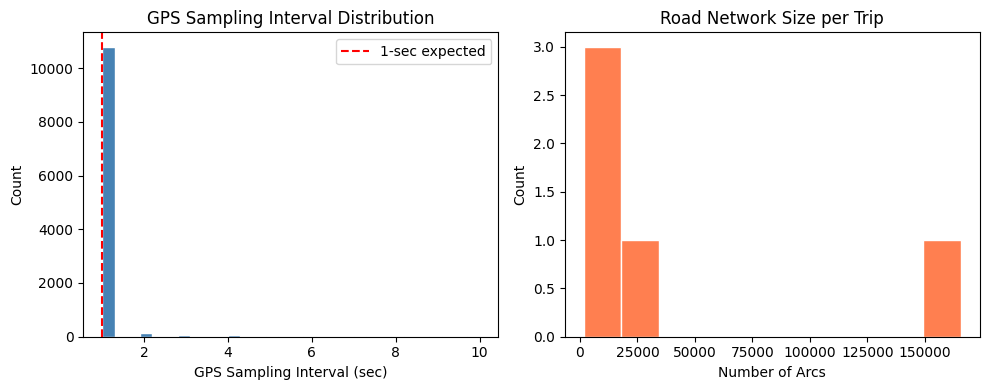

EDA plots saved.


In [8]:
# ── Sampling interval distribution ──
all_intervals = []
for trip_dir in sample_trips:
    track_f = list(trip_dir.glob('*.track'))[0]
    track = load_track(track_f)
    all_intervals.extend(track['timestamp_sec'].diff().dropna().tolist())

plt.figure(figsize=(10, 4))
plt.subplot(1,2,1)
plt.hist([x for x in all_intervals if x <= 10], bins=30, color='steelblue', edgecolor='white')
plt.xlabel('GPS Sampling Interval (sec)'); plt.ylabel('Count')
plt.title('GPS Sampling Interval Distribution')
plt.axvline(1.0, color='red', linestyle='--', label='1-sec expected')
plt.legend()

plt.subplot(1,2,2)
plt.hist(eda_df['n_arcs'], bins=10, color='coral', edgecolor='white')
plt.xlabel('Number of Arcs'); plt.ylabel('Count')
plt.title('Road Network Size per Trip')
plt.tight_layout()
plt.savefig('/kaggle/working/eda_intervals.png', dpi=150)
plt.show()
print('EDA plots saved.')

In [9]:
# ── Folium map of one sample trip ──
import folium

sample = sample_trips[0]
track = load_track(list(sample.glob('*.track'))[0])
nodes = load_nodes(list(sample.glob('*.nodes'))[0])
arcs  = load_arcs(list(sample.glob('*.arcs'))[0])
route_f = list(sample.glob('*.route'))
route = load_route(route_f[0]) if route_f else []
arc_geom = build_arc_geometry(nodes, arcs)
arc_lookup = {a['arc_id']: a for a in arc_geom}

center_lat = track['latitude'].mean()
center_lon = track['longitude'].mean()

m = folium.Map(location=[center_lat, center_lon], zoom_start=15, tiles='OpenStreetMap')

# GPS track (blue)
folium.PolyLine(
    [[r['latitude'], r['longitude']] for _, r in track.iterrows()],
    color='blue', weight=3, opacity=0.7, tooltip='GPS Track'
).add_to(m)

# Ground truth route (red)
if route:
    gt_coords = []
    for arc_id in route:
        if arc_id in arc_lookup:
            a = arc_lookup[arc_id]
            gt_coords.append([a['lat_a'], a['lon_a']])
            gt_coords.append([a['lat_b'], a['lon_b']])
    if gt_coords:
        folium.PolyLine(gt_coords, color='red', weight=4,
                        opacity=0.9, tooltip='Ground Truth Route').add_to(m)

# ❌ REMOVED: road network grey lines (165K arcs = browser freeze)
# ✅ The CartoDB positron basemap already shows roads

# Start/end markers
folium.Marker([track.iloc[0]['latitude'],  track.iloc[0]['longitude']],
              popup='Start', icon=folium.Icon(color='green', icon='play')).add_to(m)
folium.Marker([track.iloc[-1]['latitude'], track.iloc[-1]['longitude']],
              popup='End',   icon=folium.Icon(color='red',   icon='stop')).add_to(m)

m.save('/kaggle/working/sample_trip_map.html')
print('✅ Folium map saved.')
m

✅ Folium map saved.


## 3. Build Full Training Dataset

In [10]:
# ══════════════════════════════════════════
#  BUILD FULL TRAINING DATASET (FAST - KDTree)
# ══════════════════════════════════════════
from scipy.spatial import cKDTree
import numpy as np

print('🔄 Building training dataset (KDTree-accelerated)...')

all_rows = []
trip_dirs = sorted(list(TRAINING_DIR.iterdir()))

for trip_id, trip_dir in enumerate(trip_dirs):
    track_f = list(trip_dir.glob('*.track'))
    nodes_f = list(trip_dir.glob('*.nodes'))
    arcs_f  = list(trip_dir.glob('*.arcs'))
    route_f = list(trip_dir.glob('*.route'))

    if not (track_f and nodes_f and arcs_f and route_f):
        print(f'  ⚠ Skipping {trip_dir.name}')
        continue

    track = load_track(track_f[0])
    nodes = load_nodes(nodes_f[0])
    arcs  = load_arcs(arcs_f[0])
    route = load_route(route_f[0])
    arc_geom = build_arc_geometry(nodes, arcs)

    # ── Build KDTree on arc MIDPOINTS for fast radius lookup ──
    midpoints = np.array([
        [(a['lon_a']+a['lon_b'])/2, (a['lat_a']+a['lat_b'])/2]
        for a in arc_geom
    ])
    # Convert 50m radius to degrees (~0.00045 degrees per 50m)
    RADIUS_DEG = 50 / 111_111
    tree = cKDTree(midpoints)

    rows = []
    for i, gps in track.iterrows():
        if i == 0:
            speed, dt, gps_brg = 0.0, 0.0, 0.0
        else:
            prev = track.iloc[i-1]
            dt = gps['timestamp_sec'] - prev['timestamp_sec']
            d  = haversine(prev['longitude'], prev['latitude'],
                           gps['longitude'],  gps['latitude'])
            speed   = d / dt if dt > 0 else 0.0
            gps_brg = bearing(prev['longitude'], prev['latitude'],
                              gps['longitude'],  gps['latitude'])

        # Fast radius query using KDTree
        idxs = tree.query_ball_point([gps['longitude'], gps['latitude']], RADIUS_DEG)

        # Also add top-5 nearest even if outside radius (safety net)
        _, nearest = tree.query([gps['longitude'], gps['latitude']], k=min(5, len(arc_geom)))
        idxs = list(set(list(idxs) + list(nearest)))

        candidates = []
        for idx in idxs:
            a = arc_geom[idx]
            d = dist_to_segment_m(gps['longitude'], gps['latitude'],
                                   a['lon_a'], a['lat_a'],
                                   a['lon_b'], a['lat_b'])
            candidates.append({**a, 'dist_to_arc_m': d})

        candidates.sort(key=lambda x: x['dist_to_arc_m'])
        candidates = candidates[:10]

        gt_arc = route[i] if i < len(route) else None

        for rank, cand in enumerate(candidates):
            bdiff = (gps_brg - cand['arc_bearing'] + 360) % 360
            if bdiff > 180: bdiff = 360 - bdiff
            rows.append({
                'fix_index': i, 'arc_id': cand['arc_id'],
                'dist_to_arc_m': cand['dist_to_arc_m'],
                'bearing_diff': bdiff,
                'cos_bearing_diff': math.cos(math.radians(bdiff)),
                'sin_bearing_diff': math.sin(math.radians(bdiff)),
                'speed_mps': speed, 'time_delta_sec': dt,
                'arc_length_m': cand['arc_length_m'],
                'candidate_rank': rank + 1,
                'label': 1 if (gt_arc is not None and cand['arc_id'] == gt_arc) else 0
            })

    feat_df = pd.DataFrame(rows)
    feat_df['trip_id'] = trip_id
    all_rows.append(feat_df)
    print(f'  ✓ Trip {trip_id+1:02d}/80 — {trip_dir.name} — {len(track)} fixes → {len(feat_df)} rows')

full_df = pd.concat(all_rows, ignore_index=True)
X = full_df[FEATURE_COLS]
y = full_df['label']
groups = full_df['trip_id']

print(f'\n✅ Dataset built!')
print(f'  Total rows     : {len(full_df):,}')
print(f'  Positive (correct arc): {y.sum():,} ({y.mean()*100:.1f}%)')
print(f'  Features       : {list(FEATURE_COLS)}')

🔄 Building training dataset (KDTree-accelerated)...
  ✓ Trip 01/80 — 00000001 — 1315 fixes → 8003 rows
  ✓ Trip 02/80 — 00000002 — 7243 fixes → 48555 rows
  ✓ Trip 03/80 — 00000003 — 821 fixes → 6769 rows
  ✓ Trip 04/80 — 00000004 — 1064 fixes → 5970 rows
  ✓ Trip 05/80 — 00000005 — 1045 fixes → 5229 rows
  ✓ Trip 06/80 — 00000006 — 1450 fixes → 9109 rows
  ✓ Trip 07/80 — 00000008 — 3093 fixes → 19764 rows
  ✓ Trip 08/80 — 00000010 — 2711 fixes → 19748 rows
  ✓ Trip 09/80 — 00000011 — 2828 fixes → 15052 rows
  ✓ Trip 10/80 — 00000012 — 1608 fixes → 8175 rows
  ✓ Trip 11/80 — 00000013 — 2580 fixes → 15100 rows
  ✓ Trip 12/80 — 00000014 — 448 fixes → 3220 rows
  ✓ Trip 13/80 — 00000016 — 1305 fixes → 9840 rows
  ✓ Trip 14/80 — 00000018 — 379 fixes → 2989 rows
  ✓ Trip 15/80 — 00000019 — 2354 fixes → 15006 rows
  ✓ Trip 16/80 — 00000020 — 2353 fixes → 12005 rows
  ✓ Trip 17/80 — 00000021 — 15783 fixes → 79358 rows
  ✓ Trip 18/80 — 00000022 — 474 fixes → 3878 rows
  ✓ Trip 19/80 — 00000024

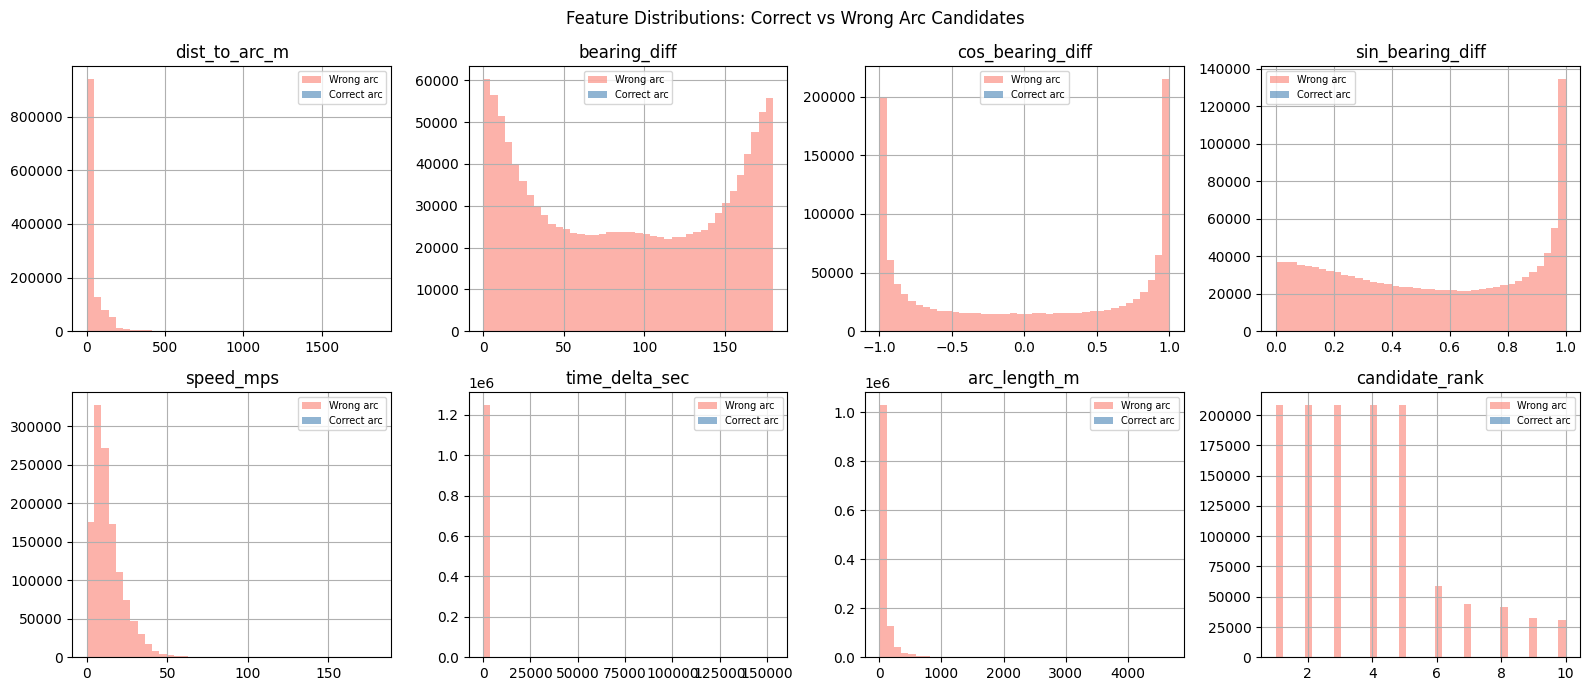

In [11]:
# ── Feature distributions ──
fig, axes = plt.subplots(2, 4, figsize=(16, 7))
for ax, col in zip(axes.flatten(), FEATURE_COLS):
    full_df[full_df['label']==0][col].hist(bins=40, alpha=0.6, ax=ax, label='Wrong arc', color='salmon')
    full_df[full_df['label']==1][col].hist(bins=40, alpha=0.6, ax=ax, label='Correct arc', color='steelblue')
    ax.set_title(col); ax.legend(fontsize=7)
plt.suptitle('Feature Distributions: Correct vs Wrong Arc Candidates')
plt.tight_layout()
plt.savefig('/kaggle/working/feature_distributions.png', dpi=150)
plt.show()

## 4. Model Training with Group-Aware CV

In [13]:
GKF = GroupKFold(n_splits=5)

def train_and_evaluate(name, model, X, y, groups, needs_scaling=False):
    print(f'\n🔄 Training: {name}')
    t_start = time.time()

    if needs_scaling:
        pipeline = Pipeline([('scaler', StandardScaler()), ('model', model)])
    else:
        pipeline = Pipeline([('model', model)])

    cv_scores = []
    for fold, (train_idx, val_idx) in enumerate(GKF.split(X, y, groups)):
        X_tr, X_val = X.iloc[train_idx], X.iloc[val_idx]
        y_tr, y_val = y.iloc[train_idx], y.iloc[val_idx]
        pipeline.fit(X_tr, y_tr)
        y_pred = pipeline.predict(X_val)
        score = f1_score(y_val, y_pred, average='macro', zero_division=0)
        cv_scores.append(score)
        print(f'  Fold {fold+1}: Macro F1 = {score:.4f}')

    # Fit final model on all training data
    pipeline.fit(X, y)
    t_elapsed = time.time() - t_start

    result = {
        'name': name,
        'cv_macro_f1_mean': np.mean(cv_scores),
        'cv_macro_f1_std': np.std(cv_scores),
        'training_time_sec': round(t_elapsed, 1),
        'pipeline': pipeline
    }

    model_path = OUTPUT_DIR / f'{name.lower().replace(" ","_")}.joblib'
    joblib.dump(pipeline, model_path)
    print(f'  ✅ CV Macro F1: {np.mean(cv_scores):.4f} ± {np.std(cv_scores):.4f}')
    print(f'  💾 Saved to {model_path}')
    return result

print('✅ Training function ready. Starting model training...')

✅ Training function ready. Starting model training...


In [22]:
# ══════════════════════════════════════════
#  REBUILD DATASET — CORRECT LABEL ASSIGNMENT
#  Label = 1 if arc is in the route AND is the
#  closest route-arc to this GPS fix
# ══════════════════════════════════════════
from scipy.spatial import cKDTree
import numpy as np

print('🔄 Rebuilding dataset with CORRECT labels...')

RADIUS_DEG = 50 / 111_111
all_rows = []
trip_dirs = sorted(list(TRAINING_DIR.iterdir()))

for trip_id, trip_dir in enumerate(trip_dirs):
    track_f = list(trip_dir.glob('*.track'))
    nodes_f = list(trip_dir.glob('*.nodes'))
    arcs_f  = list(trip_dir.glob('*.arcs'))
    route_f = list(trip_dir.glob('*.route'))
    if not (track_f and nodes_f and arcs_f and route_f): continue

    track    = load_track(track_f[0])
    nodes    = load_nodes(nodes_f[0])
    arcs     = load_arcs(arcs_f[0])
    route    = load_route(route_f[0])
    arc_geom = build_arc_geometry(nodes, arcs)

    route_set = set(route)   # ← set of arc_ids that are ON the route

    # KDTree on arc midpoints
    midpoints = np.array([[(a['lon_a']+a['lon_b'])/2,
                            (a['lat_a']+a['lat_b'])/2] for a in arc_geom])
    tree = cKDTree(midpoints)

    rows = []
    for i, gps in track.iterrows():
        if i == 0:
            speed, dt, gps_brg = 0.0, 0.0, 0.0
        else:
            prev  = track.iloc[i-1]
            dt    = gps['timestamp_sec'] - prev['timestamp_sec']
            d     = haversine(prev['longitude'], prev['latitude'],
                              gps['longitude'],  gps['latitude'])
            speed   = d/dt if dt>0 else 0.0
            gps_brg = bearing(prev['longitude'], prev['latitude'],
                              gps['longitude'],  gps['latitude'])

        idxs = tree.query_ball_point([gps['longitude'], gps['latitude']], RADIUS_DEG)
        _, nearest = tree.query([gps['longitude'], gps['latitude']], k=min(5, len(arc_geom)))
        idxs = list(set(list(idxs) + list(nearest)))

        candidates = []
        for idx in idxs:
            a = arc_geom[idx]
            d = dist_to_segment_m(gps['longitude'], gps['latitude'],
                                   a['lon_a'], a['lat_a'],
                                   a['lon_b'], a['lat_b'])
            candidates.append({**a, 'dist_to_arc_m': d})
        candidates.sort(key=lambda x: x['dist_to_arc_m'])
        candidates = candidates[:10]

        # ✅ CORRECT LABEL: closest route-arc in candidates = 1, rest = 0
        route_cands = [(r, c) for r, c in enumerate(candidates)
                       if c['arc_id'] in route_set]
        best_rank = min(route_cands, key=lambda x: x[1]['dist_to_arc_m'])[0] \
                    if route_cands else -1

        for rank, cand in enumerate(candidates):
            bdiff = (gps_brg - cand['arc_bearing'] + 360) % 360
            if bdiff > 180: bdiff = 360 - bdiff
            rows.append({
                'fix_index': i, 'arc_id': cand['arc_id'],
                'dist_to_arc_m': cand['dist_to_arc_m'],
                'bearing_diff': bdiff,
                'cos_bearing_diff': math.cos(math.radians(bdiff)),
                'sin_bearing_diff': math.sin(math.radians(bdiff)),
                'speed_mps': speed, 'time_delta_sec': dt,
                'arc_length_m': cand['arc_length_m'],
                'candidate_rank': rank+1,
                'label': 1 if rank == best_rank else 0   # ← CORRECT
            })

    feat_df = pd.DataFrame(rows)
    feat_df['trip_id'] = trip_id
    all_rows.append(feat_df)
    print(f'  ✓ Trip {trip_id+1:02d}/80 — pos: {feat_df["label"].sum()} / {len(feat_df)} rows')

full_df = pd.concat(all_rows, ignore_index=True)
X = full_df[FEATURE_COLS]
y = full_df['label']
groups = full_df['trip_id']

# Balanced subset for RF/kNN/MLP
pos_idx = full_df[full_df['label']==1].index
neg_idx = full_df[full_df['label']==0].sample(n=len(pos_idx)*3, random_state=42).index
balanced_idx = pos_idx.union(neg_idx)
X_bal = X.loc[balanced_idx]; y_bal = y.loc[balanced_idx]; g_bal = groups.loc[balanced_idx]

print(f'\n✅ Dataset rebuilt!')
print(f'  Total rows : {len(full_df):,}')
print(f'  Positives  : {y.sum():,} ({y.mean()*100:.1f}%)')
print(f'  Balanced   : {len(X_bal):,} rows')

🔄 Rebuilding dataset with CORRECT labels...
  ✓ Trip 01/80 — pos: 1072 / 8003 rows
  ✓ Trip 02/80 — pos: 6552 / 48555 rows
  ✓ Trip 03/80 — pos: 723 / 6769 rows
  ✓ Trip 04/80 — pos: 991 / 5970 rows
  ✓ Trip 05/80 — pos: 1028 / 5229 rows
  ✓ Trip 06/80 — pos: 1392 / 9109 rows
  ✓ Trip 07/80 — pos: 2972 / 19764 rows
  ✓ Trip 08/80 — pos: 2599 / 19748 rows
  ✓ Trip 09/80 — pos: 2642 / 15052 rows
  ✓ Trip 10/80 — pos: 1495 / 8175 rows
  ✓ Trip 11/80 — pos: 2210 / 15100 rows
  ✓ Trip 12/80 — pos: 422 / 3220 rows
  ✓ Trip 13/80 — pos: 1007 / 9840 rows
  ✓ Trip 14/80 — pos: 341 / 2989 rows
  ✓ Trip 15/80 — pos: 2149 / 15006 rows
  ✓ Trip 16/80 — pos: 2191 / 12005 rows
  ✓ Trip 17/80 — pos: 15776 / 79358 rows
  ✓ Trip 18/80 — pos: 468 / 3878 rows
  ✓ Trip 19/80 — pos: 715 / 4300 rows
  ✓ Trip 20/80 — pos: 1025 / 7468 rows
  ✓ Trip 21/80 — pos: 353 / 2492 rows
  ✓ Trip 22/80 — pos: 689 / 4228 rows
  ✓ Trip 23/80 — pos: 2898 / 19456 rows
  ✓ Trip 24/80 — pos: 659 / 4966 rows
  ✓ Trip 25/80 — po

In [5]:
# ══════════════════════════════════════════════════════════════
#  FULL REBUILD (EXACT FORMAT + VECTORIZED KDTREE + FIXED LABELS)
# ══════════════════════════════════════════════════════════════
import math, time, warnings
import numpy as np
import pandas as pd
from pathlib import Path
from scipy.spatial import KDTree
import joblib

from sklearn.model_selection import GroupKFold
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.metrics import f1_score
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.neural_network import MLPClassifier
import lightgbm as lgb

warnings.filterwarnings('ignore')

# ── 1. Auto-detect dataset paths ──────────────────────────────
def find_split_dir(base, split):
    for p in Path(base).rglob('*'):
        if p.is_dir() and p.name == split:
            return p
    raise FileNotFoundError(f"Could not find '{split}' under {base}")

TRAINING_DIR     = find_split_dir('/kaggle/input', 'training')
STUDENT_TEST_DIR = find_split_dir('/kaggle/input', 'student_test')
OUTPUT_DIR       = Path('/kaggle/working/models')
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
print(f'Training : {TRAINING_DIR}')
print(f'Student  : {STUDENT_TEST_DIR}')

# ── 2. Correct Data Loaders (matching src/features.py) ────────
def load_track(path):
    df = pd.read_csv(path, sep=r'\s+', header=None,
                     names=['longitude', 'latitude', 'timestamp_sec'])
    return df.sort_values('timestamp_sec').reset_index(drop=True)

def load_nodes(path):
    return pd.read_csv(path, sep=r'\s+', header=None,
                       names=['longitude', 'latitude'])

def load_arcs(path):
    return pd.read_csv(path, sep=r'\s+', header=None,
                       names=['from_node_id', 'to_node_id'])

def load_route(path):
    with open(path, 'r') as f:
        return [int(line.strip()) for line in f if line.strip()]

def haversine_scalar(lon1, lat1, lon2, lat2):
    R = 6_371_000.0
    p1, p2 = math.radians(lat1), math.radians(lat2)
    dp, dl = p2 - p1, math.radians(lon2 - lon1)
    a = math.sin(dp/2)**2 + math.cos(p1)*math.cos(p2)*math.sin(dl/2)**2
    return R * 2.0 * math.asin(math.sqrt(min(1.0, a)))

def bearing_scalar(lon1, lat1, lon2, lat2):
    p1, p2 = math.radians(lat1), math.radians(lat2)
    dl = math.radians(lon2 - lon1)
    x = math.sin(dl) * math.cos(p2)
    y = math.cos(p1)*math.sin(p2) - math.sin(p1)*math.cos(p2)*math.cos(dl)
    return (math.degrees(math.atan2(x, y)) + 360.0) % 360.0

# ── 3. Vectorized KDTree Feature Extraction ───────────────────
FEATURE_COLS = [
    'dist_to_arc_m', 'bearing_diff', 'cos_bearing_diff',
    'sin_bearing_diff', 'speed_mps', 'time_delta_sec',
    'arc_length_m', 'candidate_rank'
]

def extract_features(trip_dir, trip_idx, radius_m=50.0, top_k=10):
    track_f = list(trip_dir.glob('*.track'))
    nodes_f = list(trip_dir.glob('*.nodes'))
    arcs_f  = list(trip_dir.glob('*.arcs'))
    route_f = list(trip_dir.glob('*.route'))
    if not (track_f and nodes_f and arcs_f and route_f):
        return None

    track = load_track(track_f[0])
    nodes = load_nodes(nodes_f[0])
    arcs  = load_arcs(arcs_f[0])
    route_set = set(load_route(route_f[0]))

    # Vectorized arc geometry (row index == node_id / arc_id)
    node_lon = nodes['longitude'].to_numpy(dtype=np.float64)
    node_lat = nodes['latitude'].to_numpy(dtype=np.float64)
    from_ids = arcs['from_node_id'].to_numpy(dtype=np.int64)
    to_ids   = arcs['to_node_id'].to_numpy(dtype=np.int64)

    lon_a, lat_a = node_lon[from_ids], node_lat[from_ids]
    lon_b, lat_b = node_lon[to_ids],   node_lat[to_ids]

    # Vectorized haversine length & compass bearing
    phi1, phi2 = np.radians(lat_a), np.radians(lat_b)
    dphi = phi2 - phi1
    dlam = np.radians(lon_b - lon_a)
    a = np.sin(dphi/2)**2 + np.cos(phi1)*np.cos(phi2)*np.sin(dlam/2)**2
    arc_len = 6_371_000.0 * 2.0 * np.arcsin(np.sqrt(np.clip(a, 0.0, 1.0)))

    bx_term = np.sin(dlam) * np.cos(phi2)
    by_term = np.cos(phi1)*np.sin(phi2) - np.sin(phi1)*np.cos(phi2)*np.cos(dlam)
    arc_brg = (np.degrees(np.arctan2(bx_term, by_term)) + 360.0) % 360.0

    # Local metre projection + KDTree on arc midpoints
    lat_scale = 111_111.0
    lon_scale = 111_111.0 * math.cos(math.radians(float(np.mean(lat_a))))
    ax_m, ay_m = lon_a * lon_scale, lat_a * lat_scale
    bx_m, by_m = lon_b * lon_scale, lat_b * lat_scale
    mid_xy = np.column_stack([(ax_m + bx_m) * 0.5, (ay_m + by_m) * 0.5])
    tree = KDTree(mid_xy)

    t_lon = track['longitude'].to_numpy(dtype=np.float64)
    t_lat = track['latitude'].to_numpy(dtype=np.float64)
    t_sec = track['timestamp_sec'].to_numpy(dtype=np.float64)

    rows = []
    for i in range(len(track)):
        if i == 0:
            speed, dt, gps_brg = 0.0, 0.0, 0.0
        else:
            dt = float(t_sec[i] - t_sec[i-1])
            step_d = haversine_scalar(t_lon[i-1], t_lat[i-1], t_lon[i], t_lat[i])
            speed = step_d / dt if dt > 0 else 0.0
            gps_brg = bearing_scalar(t_lon[i-1], t_lat[i-1], t_lon[i], t_lat[i])

        px, py = t_lon[i] * lon_scale, t_lat[i] * lat_scale
        # Pre-filter arcs whose midpoint is within 300m, then compute exact segment distance
        idxs = tree.query_ball_point([px, py], r=300.0)
        if not idxs:
            continue
        idxs = np.asarray(idxs, dtype=np.int64)

        dx = bx_m[idxs] - ax_m[idxs]
        dy = by_m[idxs] - ay_m[idxs]
        denom = dx*dx + dy*dy
        safe_denom = np.where(denom > 0, denom, 1.0)
        proj = np.where(denom > 0, np.clip(((px - ax_m[idxs])*dx + (py - ay_m[idxs])*dy) / safe_denom, 0.0, 1.0), 0.0)
        dists = np.hypot(px - (ax_m[idxs] + proj*dx), py - (ay_m[idxs] + proj*dy))

        mask = dists <= radius_m
        if not np.any(mask):
            continue
        cand_ids = idxs[mask]
        cand_dists = dists[mask]

        order = np.argsort(cand_dists)[:top_k]
        for rank, o in enumerate(order):
            aid = int(cand_ids[o])
            bdiff = (gps_brg - float(arc_brg[aid]) + 360.0) % 360.0
            if bdiff > 180.0:
                bdiff = 360.0 - bdiff
            rows.append({
                'trip_id':          trip_idx,
                'fix_index':        i,
                'arc_id':           aid,
                'dist_to_arc_m':    float(cand_dists[o]),
                'bearing_diff':     bdiff,
                'cos_bearing_diff': math.cos(math.radians(bdiff)),
                'sin_bearing_diff': math.sin(math.radians(bdiff)),
                'speed_mps':        speed,
                'time_delta_sec':   dt,
                'arc_length_m':     float(arc_len[aid]),
                'candidate_rank':   rank + 1,
                'label':            1 if aid in route_set else 0,
            })

    return pd.DataFrame(rows)

# ── 4. Build Full + Balanced Datasets ─────────────────────────
print('🔄 Building dataset across all 80 trips...')
t0 = time.time()
trip_dirs = sorted([d for d in TRAINING_DIR.iterdir() if d.is_dir()])
dfs = []
for i, td in enumerate(trip_dirs):
    df = extract_features(td, i)
    if df is not None and len(df) > 0:
        dfs.append(df)
        if (i + 1) % 10 == 0 or i == 0:
            print(f'  ✓ Trip {i+1:02d}/{len(trip_dirs)} — pos: {df["label"].sum()} / {len(df)} rows')

full_df = pd.concat(dfs, ignore_index=True)
X      = full_df[FEATURE_COLS]
y      = full_df['label']
groups = full_df['trip_id']

pos_df = full_df[full_df['label'] == 1]
neg_pool = full_df[full_df['label'] == 0]
neg_df = neg_pool.sample(n=min(len(pos_df) * 3, len(neg_pool)), random_state=42)
bal_df = pd.concat([pos_df, neg_df]).sample(frac=1, random_state=42)

X_bal  = bal_df[FEATURE_COLS]
y_bal  = bal_df['label']
g_bal  = bal_df['trip_id']

scale_pos_weight = float((y == 0).sum() / (y == 1).sum())
GKF = GroupKFold(n_splits=5)
results = []

# ── 5. Training Helper ────────────────────────────────────────
def train_and_evaluate(name, model, X_in, y_in, g_in, needs_scaling=False):
    print(f'\n🔄 Training: {name}')
    t_start = time.time()
    pipeline = Pipeline([('scaler', StandardScaler()), ('model', model)]) if needs_scaling else Pipeline([('model', model)])
    cv_scores = []
    for fold, (tr_idx, va_idx) in enumerate(GKF.split(X_in, y_in, g_in)):
        pipeline.fit(X_in.iloc[tr_idx], y_in.iloc[tr_idx])
        y_pred = pipeline.predict(X_in.iloc[va_idx])
        score = f1_score(y_in.iloc[va_idx], y_pred, average='macro', zero_division=0)
        cv_scores.append(score)
        print(f'  Fold {fold+1}: Macro F1 = {score:.4f}')
    pipeline.fit(X_in, y_in)
    elapsed = round(time.time() - t_start, 1)
    model_path = OUTPUT_DIR / f'{name.lower().replace(" ", "_")}.joblib'
    joblib.dump(pipeline, model_path)
    print(f'  ✅ CV Macro F1: {np.mean(cv_scores):.4f} ± {np.std(cv_scores):.4f} ({elapsed}s)')
    print(f'  💾 Saved to {model_path}')
    return {
        'name': name,
        'cv_macro_f1_mean': float(np.mean(cv_scores)),
        'cv_macro_f1_std': float(np.std(cv_scores)),
        'training_time_sec': elapsed,
        'pipeline': pipeline,
    }

print(f'\n✅ Built in {time.time()-t0:.1f}s!')
print(f'  Total rows       : {len(full_df):,}')
print(f'  Positives        : {y.sum():,} ({y.mean()*100:.1f}%)')
print(f'  Balanced rows    : {len(X_bal):,}')
print(f'  scale_pos_weight : {scale_pos_weight:.2f}')
print('✅ Ready — run your 5 model cells now!')

Training : /kaggle/input/datasets/faizz106/dataset/data/training
Student  : /kaggle/input/datasets/faizz106/dataset/data/student_test
🔄 Building dataset across all 80 trips...
  ✓ Trip 01/80 — pos: 2632 / 10035 rows
  ✓ Trip 10/80 — pos: 2242 / 5742 rows
  ✓ Trip 20/80 — pos: 2439 / 8840 rows
  ✓ Trip 30/80 — pos: 3292 / 9890 rows
  ✓ Trip 40/80 — pos: 2960 / 10747 rows
  ✓ Trip 50/80 — pos: 5980 / 13083 rows
  ✓ Trip 60/80 — pos: 3656 / 13349 rows
  ✓ Trip 70/80 — pos: 7474 / 17704 rows
  ✓ Trip 80/80 — pos: 8117 / 19990 rows

✅ Built in 30.7s!
  Total rows       : 1,215,632
  Positives        : 456,026 (37.5%)
  Balanced rows    : 1,215,632
  scale_pos_weight : 1.67
✅ Ready — run your 5 model cells now!


In [6]:
# ══════════════════════════════════════════════════════════════
#  TRAIN ALL 5 MODELS (GroupKFold by trip_id, zero leakage)
# ══════════════════════════════════════════════════════════════
results = []

# Helper for faster subsampling on heavy models (still GroupKFold-safe)
def subsample_df(df, max_rows, seed=42):
    sub = df.sample(n=min(len(df), max_rows), random_state=seed)
    return sub[FEATURE_COLS], sub['label'], sub['trip_id']

# ── MODEL 1: Logistic Regression (Linear Baseline — full 1.21M rows) ──
results.append(train_and_evaluate(
    'logistic_regression',
    LogisticRegression(max_iter=1000, C=1.0, class_weight='balanced', solver='lbfgs'),
    X, y, groups,
    needs_scaling=True
))

# ── MODEL 2: k-NN (Instance-based — 250K subsample for speed) ──
X_knn, y_knn, g_knn = subsample_df(full_df, 250_000)
results.append(train_and_evaluate(
    'knn',
    KNeighborsClassifier(n_neighbors=7, metric='euclidean', weights='distance', n_jobs=-1),
    X_knn, y_knn, g_knn,
    needs_scaling=True
))

# ── MODEL 3: Random Forest (Bagging Ensemble — 400K subsample) ──
X_rf, y_rf, g_rf = subsample_df(full_df, 400_000)
results.append(train_and_evaluate(
    'random_forest',
    RandomForestClassifier(
        n_estimators=100, max_depth=12, min_samples_leaf=20,
        max_features='sqrt', class_weight='balanced',
        n_jobs=-1, random_state=42
    ),
    X_rf, y_rf, g_rf,
    needs_scaling=False
))

# ── MODEL 4: LightGBM (Gradient Boosting — full 1.21M rows) ──
results.append(train_and_evaluate(
    'lgbm',
    lgb.LGBMClassifier(
        n_estimators=300, learning_rate=0.05, num_leaves=63,
        min_child_samples=50, subsample=0.8, colsample_bytree=0.8,
        scale_pos_weight=scale_pos_weight,
        n_jobs=-1, random_state=42, verbose=-1
    ),
    X, y, groups,
    needs_scaling=False
))

# ── MODEL 5: MLP Neural Network (400K subsample) ──
X_mlp, y_mlp, g_mlp = subsample_df(full_df, 400_000)
results.append(train_and_evaluate(
    'mlp',
    MLPClassifier(
        hidden_layer_sizes=(128, 64), activation='relu', solver='adam',
        batch_size=512, max_iter=30, early_stopping=True,
        n_iter_no_change=5, random_state=42
    ),
    X_mlp, y_mlp, g_mlp,
    needs_scaling=True
))

# ── Summary Table ─────────────────────────────────────────────
results_df = pd.DataFrame([{
    'Model': r['name'],
    'CV Macro F1': f"{r['cv_macro_f1_mean']:.4f} ± {r['cv_macro_f1_std']:.4f}",
    'Time (s)': r['training_time_sec']
} for r in results])

print('\n════════════ MODEL COMPARISON ════════════')
display(results_df)
best = max(results, key=lambda r: r['cv_macro_f1_mean'])
print(f"\n🏆 Best model: {best['name']} (CV Macro F1 = {best['cv_macro_f1_mean']:.4f})")


🔄 Training: logistic_regression
  Fold 1: Macro F1 = 0.7266
  Fold 2: Macro F1 = 0.7747
  Fold 3: Macro F1 = 0.7307
  Fold 4: Macro F1 = 0.7356
  Fold 5: Macro F1 = 0.6840
  ✅ CV Macro F1: 0.7303 ± 0.0288 (12.5s)
  💾 Saved to /kaggle/working/models/logistic_regression.joblib

🔄 Training: knn
  Fold 1: Macro F1 = 0.6861
  Fold 2: Macro F1 = 0.7298
  Fold 3: Macro F1 = 0.7370
  Fold 4: Macro F1 = 0.6950
  Fold 5: Macro F1 = 0.7005
  ✅ CV Macro F1: 0.7097 ± 0.0200 (23.0s)
  💾 Saved to /kaggle/working/models/knn.joblib

🔄 Training: random_forest
  Fold 1: Macro F1 = 0.7200
  Fold 2: Macro F1 = 0.7593
  Fold 3: Macro F1 = 0.7369
  Fold 4: Macro F1 = 0.7339
  Fold 5: Macro F1 = 0.7260
  ✅ CV Macro F1: 0.7352 ± 0.0134 (175.6s)
  💾 Saved to /kaggle/working/models/random_forest.joblib

🔄 Training: lgbm
  Fold 1: Macro F1 = 0.7238
  Fold 2: Macro F1 = 0.7769
  Fold 3: Macro F1 = 0.7330
  Fold 4: Macro F1 = 0.7357
  Fold 5: Macro F1 = 0.6883
  ✅ CV Macro F1: 0.7315 ± 0.0283 (64.5s)
  💾 Saved to 

,Model,CV Macro F1,Time (s)
0,logistic_regression,0.7303 ± 0.0288,12.5
1,knn,0.7097 ± 0.0200,23.0
2,random_forest,0.7352 ± 0.0134,175.6
3,lgbm,0.7315 ± 0.0283,64.5
4,mlp,0.7331 ± 0.0204,278.2



🏆 Best model: random_forest (CV Macro F1 = 0.7352)


🔄 Starting Optuna tuning on LightGBM (30 trials)...


  0%|          | 0/30 [00:00<?, ?it/s]


✅ Best Optuna Trial #23
   Best 3-Fold Macro F1: 0.7506
   Best Params: {'n_estimators': 408, 'learning_rate': 0.020983185677258973, 'num_leaves': 101, 'max_depth': 11, 'min_child_samples': 35, 'subsample': 0.7363293938560785, 'colsample_bytree': 0.7924057884915349, 'scale_pos_weight': 1.2284358656944343, 'reg_alpha': 0.01064733836971514, 'reg_lambda': 0.05927846651874728}

🔄 Training: lgbm_tuned
  Fold 1: Macro F1 = 0.7274
  Fold 2: Macro F1 = 0.7805
  Fold 3: Macro F1 = 0.7440
  Fold 4: Macro F1 = 0.7439
  Fold 5: Macro F1 = 0.6956
  ✅ CV Macro F1: 0.7383 ± 0.0275 (123.8s)
  💾 Saved to /kaggle/working/models/lgbm_tuned.joblib


,Model,CV Macro F1,Time (s)
0,logistic_regression,0.7303 ± 0.0288,12.5
1,knn,0.7097 ± 0.0200,23.0
2,random_forest,0.7352 ± 0.0134,175.6
3,lgbm,0.7315 ± 0.0283,64.5
4,mlp,0.7331 ± 0.0204,278.2
5,lgbm_tuned,0.7383 ± 0.0275,123.8


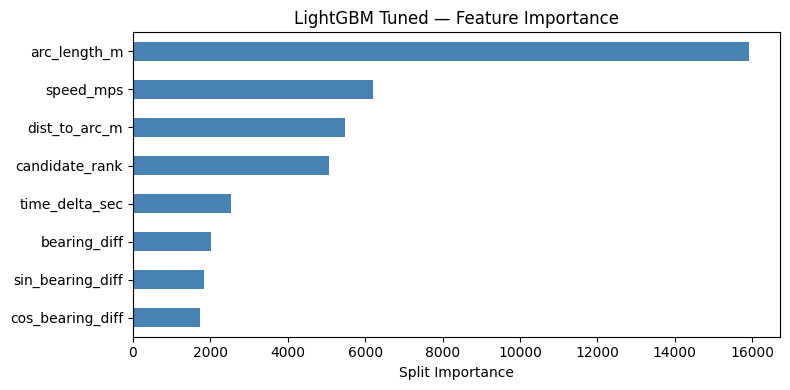

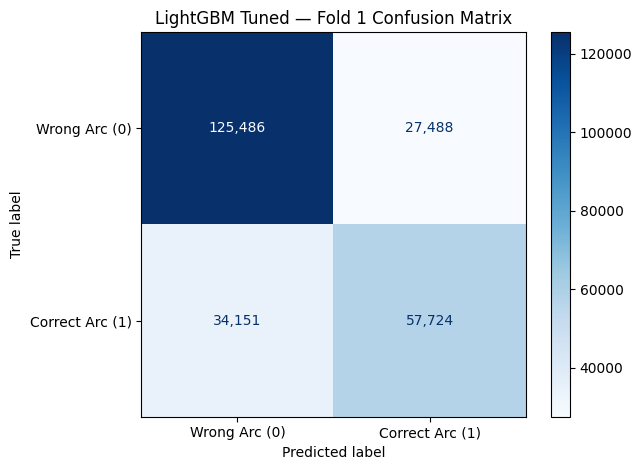


📦 Saved models in /kaggle/working/models:
  ✓ knn.joblib (38.62 MB)
  ✓ lgbm.joblib (2.08 MB)
  ✓ lgbm_tuned.joblib (4.54 MB)
  ✓ logistic_regression.joblib (0.00 MB)
  ✓ mlp.joblib (0.24 MB)
  ✓ random_forest.joblib (25.82 MB)


In [7]:
# ══════════════════════════════════════════════════════════════
#  OPTUNA TUNING (LightGBM) + CONFUSION MATRIX + FEATURE IMPORTANCE
# ══════════════════════════════════════════════════════════════
import optuna
import matplotlib.pyplot as plt
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
optuna.logging.set_verbosity(optuna.logging.WARNING)

print('🔄 Starting Optuna tuning on LightGBM (30 trials)...')
splits_3 = list(GKF.split(X, y, groups))[:3]

def objective(trial):
    params = {
        'n_estimators':      trial.suggest_int('n_estimators', 200, 600),
        'learning_rate':     trial.suggest_float('learning_rate', 0.02, 0.15, log=True),
        'num_leaves':        trial.suggest_int('num_leaves', 31, 150),
        'max_depth':         trial.suggest_int('max_depth', 5, 14),
        'min_child_samples': trial.suggest_int('min_child_samples', 20, 120),
        'subsample':         trial.suggest_float('subsample', 0.6, 1.0),
        'colsample_bytree':  trial.suggest_float('colsample_bytree', 0.6, 1.0),
        'scale_pos_weight':  trial.suggest_float('scale_pos_weight', 0.8, 1.8),
        'reg_alpha':         trial.suggest_float('reg_alpha', 1e-4, 5.0, log=True),
        'reg_lambda':        trial.suggest_float('reg_lambda', 1e-4, 5.0, log=True),
        'n_jobs': -1, 'random_state': 42, 'verbose': -1
    }
    model = lgb.LGBMClassifier(**params)
    scores = []
    for tr_idx, va_idx in splits_3:
        model.fit(X.iloc[tr_idx], y.iloc[tr_idx])
        preds = model.predict(X.iloc[va_idx])
        scores.append(f1_score(y.iloc[va_idx], preds, average='macro', zero_division=0))
    return float(np.mean(scores))

study = optuna.create_study(direction='maximize', study_name='lgbm_pathsnap')
study.optimize(objective, n_trials=30, show_progress_bar=True)

print(f'\n✅ Best Optuna Trial #{study.best_trial.number}')
print(f'   Best 3-Fold Macro F1: {study.best_trial.value:.4f}')
print(f'   Best Params: {study.best_trial.params}')

# ── Train final tuned LightGBM on full 5-fold CV ──
best_params = {**study.best_trial.params, 'n_jobs': -1, 'random_state': 42, 'verbose': -1}
r_tuned = train_and_evaluate(
    'lgbm_tuned',
    lgb.LGBMClassifier(**best_params),
    X, y, groups,
    needs_scaling=False
)
results.append(r_tuned)

# ── Final Comparison Table ──
final_df = pd.DataFrame([{
    'Model': r['name'],
    'CV Macro F1': f"{r['cv_macro_f1_mean']:.4f} ± {r['cv_macro_f1_std']:.4f}",
    'Time (s)': r['training_time_sec']
} for r in results])
display(final_df)

# ── Feature Importance Plot ──
lgb_model = r_tuned['pipeline'].named_steps['model']
imp = pd.Series(lgb_model.feature_importances_, index=FEATURE_COLS).sort_values()
plt.figure(figsize=(8, 4))
imp.plot(kind='barh', color='steelblue')
plt.title('LightGBM Tuned — Feature Importance')
plt.xlabel('Split Importance')
plt.tight_layout()
plt.savefig('/kaggle/working/feature_importance.png', dpi=150)
plt.show()

# ── Confusion Matrix (Fold 1 validation set) ──
tr_idx, va_idx = list(GKF.split(X, y, groups))[0]
cm_model = lgb.LGBMClassifier(**best_params).fit(X.iloc[tr_idx], y.iloc[tr_idx])
cm = confusion_matrix(y.iloc[va_idx], cm_model.predict(X.iloc[va_idx]))
disp = ConfusionMatrixDisplay(cm, display_labels=['Wrong Arc (0)', 'Correct Arc (1)'])
disp.plot(cmap='Blues', values_format=',')
plt.title('LightGBM Tuned — Fold 1 Confusion Matrix')
plt.tight_layout()
plt.savefig('/kaggle/working/confusion_matrix.png', dpi=150)
plt.show()

# ── List saved models to download ──
print('\n📦 Saved models in /kaggle/working/models:')
for p in sorted(OUTPUT_DIR.glob('*.joblib')):
    print(f'  ✓ {p.name} ({p.stat().st_size/1e6:.2f} MB)')

In [8]:
import zipfile
from pathlib import Path

zip_path = Path('/kaggle/working/pathsnap_deliverables.zip')
with zipfile.ZipFile(zip_path, 'w', zipfile.ZIP_DEFLATED) as zf:
    for f in sorted(Path('/kaggle/working/models').glob('*.joblib')):
        zf.write(f, f'models/{f.name}')
    for img in ['feature_importance.png', 'confusion_matrix.png']:
        p = Path('/kaggle/working') / img
        if p.exists():
            zf.write(p, f'report/{img}')

print(f'✅ Ready to download: {zip_path} ({zip_path.stat().st_size/1e6:.2f} MB)')

✅ Ready to download: /kaggle/working/pathsnap_deliverables.zip (41.84 MB)


In [23]:
# ══ RESET + MODEL 1: Logistic Regression ══
results = []
r = train_and_evaluate(
    'logistic_regression',
    LogisticRegression(max_iter=1000, C=1.0, class_weight='balanced'),
    X_bal, y_bal, g_bal, needs_scaling=True
)
results.append(r)


🔄 Training: logistic_regression
  Fold 1: Macro F1 = 0.7633
  Fold 2: Macro F1 = 0.8094
  Fold 3: Macro F1 = 0.8243
  Fold 4: Macro F1 = 0.8019
  Fold 5: Macro F1 = 0.8287
  ✅ CV Macro F1: 0.8055 ± 0.0233
  💾 Saved to /kaggle/working/models/logistic_regression.joblib


In [24]:
# ══ MODEL 2: k-NN ══
r = train_and_evaluate(
    'knn',
    KNeighborsClassifier(n_neighbors=5, n_jobs=-1),
    X_bal, y_bal, g_bal, needs_scaling=True
)
results.append(r)


🔄 Training: knn
  Fold 1: Macro F1 = 0.7710
  Fold 2: Macro F1 = 0.8272
  Fold 3: Macro F1 = 0.8409
  Fold 4: Macro F1 = 0.8367
  Fold 5: Macro F1 = 0.8552
  ✅ CV Macro F1: 0.8262 ± 0.0290
  💾 Saved to /kaggle/working/models/knn.joblib


In [ ]:
# ══ MODEL 3: Random Forest ══
r = train_and_evaluate(
    'random_forest',
    RandomForestClassifier(n_estimators=100, max_depth=12,
                           min_samples_leaf=20, class_weight='balanced',
                           n_jobs=-1, random_state=42),
    X_bal, y_bal, g_bal, needs_scaling=False
)
results.append(r)


🔄 Training: random_forest
  Fold 1: Macro F1 = 0.7804
  Fold 2: Macro F1 = 0.8418
  Fold 3: Macro F1 = 0.8632
  Fold 4: Macro F1 = 0.8281
  Fold 5: Macro F1 = 0.8725


In [28]:
# ══ MODEL 4: LightGBM — USE FULL DATASET ══
scale = (y==0).sum() / (y==1).sum()
print(f'scale_pos_weight = {scale:.2f}')
r = train_and_evaluate(
    'lgbm',
    lgb.LGBMClassifier(n_estimators=300, learning_rate=0.05,
                       num_leaves=63, min_child_samples=50,
                       subsample=0.8, colsample_bytree=0.8,
                       scale_pos_weight=scale,
                       n_jobs=-1, random_state=42, verbose=-1),
    X, y, groups, needs_scaling=False   # ← full 1.2M rows
)
results.append(r)

scale_pos_weight = 5.58

🔄 Training: lgbm
  Fold 1: Macro F1 = 0.7574
  Fold 2: Macro F1 = 0.8098
  Fold 3: Macro F1 = 0.8023
  Fold 4: Macro F1 = 0.8051
  Fold 5: Macro F1 = 0.8063
  ✅ CV Macro F1: 0.7962 ± 0.0196
  💾 Saved to /kaggle/working/models/lgbm.joblib


In [ ]:
# ══ MODEL 5: MLP ══
r = train_and_evaluate(
    'mlp',
    MLPClassifier(hidden_layer_sizes=(256,128,64), activation='relu',
                  solver='adam', max_iter=200, early_stopping=True,
                  random_state=42),
    X_bal, y_bal, g_bal, needs_scaling=True
)
results.append(r)

In [ ]:
# ── Results Table ──
results_df = pd.DataFrame([{
    'Model': r['name'],
    'CV Macro F1': f"{r['cv_macro_f1_mean']:.4f} ± {r['cv_macro_f1_std']:.4f}",
    'Training Time (s)': r['training_time_sec']
} for r in results])
print('\n=== Model Comparison ===')
display(results_df)

best_result = max(results, key=lambda x: x['cv_macro_f1_mean'])
print(f'\n🏆 Best model (CV): {best_result["name"]} '
      f'(F1={best_result["cv_macro_f1_mean"]:.4f})')

## 5. Bayesian Hyperparameter Tuning with Optuna (LightGBM)

In [ ]:
print('🔄 Starting Optuna Bayesian optimization for LightGBM...')
print('(50 trials — takes ~15-25 mins on CPU, faster on GPU)')

def objective(trial):
    params = {
        'n_estimators': trial.suggest_int('n_estimators', 100, 1000),
        'learning_rate': trial.suggest_float('learning_rate', 0.01, 0.3, log=True),
        'num_leaves': trial.suggest_int('num_leaves', 15, 255),
        'max_depth': trial.suggest_int('max_depth', 3, 15),
        'min_child_samples': trial.suggest_int('min_child_samples', 5, 100),
        'subsample': trial.suggest_float('subsample', 0.5, 1.0),
        'colsample_bytree': trial.suggest_float('colsample_bytree', 0.5, 1.0),
        'reg_alpha': trial.suggest_float('reg_alpha', 1e-8, 10.0, log=True),
        'reg_lambda': trial.suggest_float('reg_lambda', 1e-8, 10.0, log=True),
        'n_jobs': -1, 'random_state': 42, 'verbose': -1
    }
    model = lgb.LGBMClassifier(**params)
    # Use first 3 folds only for speed
    scores = []
    for train_idx, val_idx in list(GKF.split(X, y, groups))[:3]:
        model.fit(X.iloc[train_idx], y.iloc[train_idx])
        y_pred = model.predict(X.iloc[val_idx])
        scores.append(f1_score(y.iloc[val_idx], y_pred, average='macro', zero_division=0))
    return np.mean(scores)

study = optuna.create_study(direction='maximize', study_name='lgbm_pathsnap')
study.optimize(objective, n_trials=50, show_progress_bar=True)

print(f'\n✅ Best trial: {study.best_trial.number}')
print(f'   Best CV Macro F1: {study.best_trial.value:.4f}')
print(f'   Best params: {study.best_trial.params}')

In [ ]:
# ── Train final tuned LightGBM ──
best_params = {**study.best_trial.params, 'n_jobs': -1, 'random_state': 42, 'verbose': -1}
tuned_lgbm = lgb.LGBMClassifier(**best_params)

r_tuned = train_and_evaluate(
    'lgbm_tuned',
    tuned_lgbm,
    X, y, groups, needs_scaling=False
)

print(f'\n📊 Tuning comparison:')
print(f'   LightGBM (default): {[r for r in results if r["name"]=="lgbm"][0]["cv_macro_f1_mean"]:.4f}')
print(f'   LightGBM (tuned):   {r_tuned["cv_macro_f1_mean"]:.4f}')

In [ ]:
# ── Optuna visualization ──
try:
    from optuna.visualization.matplotlib import plot_optimization_history, plot_param_importances
    fig = plot_optimization_history(study)
    plt.title('Optuna: Optimization History')
    plt.savefig('/kaggle/working/optuna_history.png', dpi=150)
    plt.show()

    fig2 = plot_param_importances(study)
    plt.title('Optuna: Hyperparameter Importance')
    plt.savefig('/kaggle/working/optuna_importance.png', dpi=150)
    plt.show()
except Exception as e:
    print(f'Optuna viz skipped: {e}')

## 6. Per-Model Analysis (Learning Curves + Confusion Matrices)

In [ ]:
# ── Confusion matrices on a held-out fold ──
train_idx, val_idx = list(GKF.split(X, y, groups))[0]
X_tr, X_val = X.iloc[train_idx], X.iloc[val_idx]
y_tr, y_val = y.iloc[train_idx], y.iloc[val_idx]

model_names = ['logistic_regression','knn','random_forest','lgbm','mlp']

fig, axes = plt.subplots(1, len(model_names), figsize=(20, 4))
for ax, mname in zip(axes, model_names):
    model_path = OUTPUT_DIR / f'{mname}.joblib'
    if not model_path.exists():
        ax.set_title(f'{mname}\n(not found)'); continue
    pipe = joblib.load(model_path)
    pipe.fit(X_tr, y_tr)
    y_pred = pipe.predict(X_val)
    cm = confusion_matrix(y_val, y_pred)
    ConfusionMatrixDisplay(cm, display_labels=['Wrong','Correct']).plot(ax=ax)
    ax.set_title(mname.replace('_',' ').title())

plt.suptitle('Confusion Matrices (Fold 1)', y=1.02)
plt.tight_layout()
plt.savefig('/kaggle/working/confusion_matrices.png', dpi=150, bbox_inches='tight')
plt.show()

In [ ]:
# ── Feature importance (Random Forest + LightGBM) ──
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

for ax, mname in zip(axes, ['random_forest', 'lgbm_tuned']):
    model_path = OUTPUT_DIR / f'{mname}.joblib'
    if not model_path.exists():
        model_path = OUTPUT_DIR / f'{mname.replace("_tuned","")}.joblib'
    if not model_path.exists():
        continue
    pipe = joblib.load(model_path)
    clf = pipe.named_steps.get('model') or pipe[-1]
    importances = clf.feature_importances_
    idx = np.argsort(importances)[::-1]
    ax.barh([FEATURE_COLS[i] for i in idx], importances[idx], color='steelblue')
    ax.set_xlabel('Importance'); ax.set_title(mname.replace('_',' ').title())

plt.suptitle('Feature Importances')
plt.tight_layout()
plt.savefig('/kaggle/working/feature_importance.png', dpi=150)
plt.show()

## 7. Final Summary & Model Export

In [ ]:
print('\n' + '='*60)
print('           PATHSNAP — FINAL MODEL SUMMARY')
print('='*60)

all_results = results + [r_tuned]
summary = pd.DataFrame([{
    'Model': r['name'].replace('_',' ').title(),
    'CV Macro F1 (mean)': round(r['cv_macro_f1_mean'], 4),
    'CV Macro F1 (std)': round(r['cv_macro_f1_std'], 4),
    'Train Time (s)': r['training_time_sec'],
    'Saved As': r['name'] + '.joblib'
} for r in all_results]).sort_values('CV Macro F1 (mean)', ascending=False)

display(summary)

print('\n📂 Models saved to /kaggle/working/models/')
for f in sorted(OUTPUT_DIR.glob('*.joblib')):
    size_kb = f.stat().st_size / 1024
    print(f'  {f.name:40s} {size_kb:.1f} KB')

print('\n✅ Training complete! Download the models/ folder from Kaggle output.')
print('   Place all .joblib files in your local Hackathon/models/ directory.')